# Deteksi Malicious URL Menggunakan Random Forest Classifier
## Bagian 2: Data Splitting, SMOTE, Training Random Forest, Evaluasi & Real-Time Inference (Tahap 4 - 8)

**Mata Kuliah**: Keamanan Berbasis Sistem Cerdas (UTS Semester 7)  
**Program Studi**: Teknik Informatika - Universitas Darma Persada (UNSADA)  
**Penyusun**: Sayyid Abdullah Azzam  

---

### Alur Kerja Bagian 2:
1. **Tahap 4: Data Splitting (80% Training : 20% Testing)**  
   - Membagi data terstratifikasi (`stratify=y`, `test_size=0.2`, `random_state=42`).
   - Wajib dilakukan sebelum SMOTE untuk mencegah kebocoran data (*Data Leakage*).
   - 20% Data Testing dibiarkan murni/asli.
2. **Tahap 5: Penanganan Imbalance (SMOTE)**  
   - Menganalisis rasio kelas pada Data Training.
   - Melakukan *oversampling* kelas minoritas khusus pada 80% Data Training hingga rasio seimbang 50:50 (1:1).
3. **Tahap 6: Training Model Random Forest & Penyimpanan Model**  
   - Melatih algoritma *Random Forest* (100 Decision Trees).
   - Analisis *Feature Importance* (Gini Importance).
   - Menyimpan model terlatih ke folder lokal `model/random_forest_model.joblib`.
4. **Tahap 7: Evaluasi Model (Testing)**  
   - Menguji performa model pada 20% Data Testing murni.
   - Menganalisis *Confusion Matrix*, *Accuracy*, *Precision*, *Recall* (fokus pada pendeteksian tautan berbahaya agar *False Negative* rendah), dan *F1-Score*.
5. **Tahap 8: Inference / Deployment (Uji URL Baru: Aman / Blokir)**  
   - Memuat model tersimpan dari `model/random_forest_model.joblib`.
   - Membuat fungsi interaktif `scan_url(url)` untuk mengklasifikasikan URL input menjadi **AMAN** atau **BLOKIR** beserta persentase keyakinan model (*Confidence Score*).
   - Pengujian URL kampus resmi UNSADA vs tautan serangan siber (*phishing*).

In [1]:
# ==============================================================================
# IMPORT MODUL & DEPENDENSI
# ==============================================================================
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn & Imbalanced-Learn
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score
)

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Semua pustaka pemodelan machine learning berhasil diimpor!")

Semua pustaka pemodelan machine learning berhasil diimpor!


---
### Memuat Data Fitur Hasil Preprocessing (Bagian 1)
Data fitur numerik yang telah diekstrak pada Bagian 1 dimuat langsung dari file `dataset/extracted_features.csv`.

In [2]:
# Memuat data hasil ekstraksi fitur dari folder dataset/
features_csv_path = os.path.join("dataset", "extracted_features.csv")

if not os.path.exists(features_csv_path):
    raise FileNotFoundError(f"File {features_csv_path} tidak ditemukan! Pastikan telah menjalankan notebook Bagian 1 terlebih dahulu.")

df_features = pd.read_csv(features_csv_path)
print(f"Data fitur berhasil dimuat! Dimensi: {df_features.shape[0]:,} baris dan {df_features.shape[1]} kolom.")

feature_cols = [
    'url_length', 'count_dot', 'count_hyphen', 'count_slash',
    'count_at', 'count_digits', 'has_ip', 'has_phish_keywords'
]

X = df_features[feature_cols]
y = df_features['label']

print("Daftar 8 Fitur Leksikal:")
print(feature_cols)
display(X.head())

Data fitur berhasil dimuat! Dimensi: 19,920 baris dan 11 kolom.
Daftar 8 Fitur Leksikal:
['url_length', 'count_dot', 'count_hyphen', 'count_slash', 'count_at', 'count_digits', 'has_ip', 'has_phish_keywords']


,url_length,count_dot,count_hyphen,count_slash,count_at,count_digits,has_ip,has_phish_keywords
0,38,4,0,4,0,11,1,0
1,54,2,1,1,0,0,0,0
2,26,2,0,2,0,0,0,0
3,49,3,0,6,0,3,0,0
4,121,2,5,6,0,7,0,0


---
## Tahap 4: Data Splitting (80% Training : 20% Testing)

> ⚠️ **Prinsip Fundamental: Pencegahan Data Leakage (Kebocoran Data)**  
> Pemisahan dataset (*train-test split*) **wajib dilakukan sebelum** menerapkan algoritma SMOTE.  
> Jika SMOTE diterapkan sebelum pemisahan data, sampel data sintetis dari data testing akan merembes masuk ke dalam data latih. Hal ini mengakibatkan evaluasi performa model menjadi bias, palsu, dan mengalami *overfitting* yang tidak valid di dunia nyata.

**Langkah yang Diterapkan**:
1. Membagi dataset menjadi **80% Data Training** dan **20% Data Testing** secara terstratifikasi (`stratify=y`).
2. Data Testing (20%) dibiarkan **tetap murni/asli** tanpa tersentuh SMOTE untuk menjadi instrumen evaluasi yang objektif.

In [3]:
# 1. Pemisahan Data (80% Training : 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah sampel 80% Data Latih (Training Set) : {X_train.shape[0]:,} baris")
print(f"Jumlah sampel 20% Data Uji   (Testing Set)  : {X_test.shape[0]:,} baris")

print("\nDistribusi Kelas pada Data Training SEBELUM SMOTE:")
dist_before = y_train.value_counts()
print(dist_before)
print(f"Rasio Aman : Bahaya = {dist_before[0] / dist_before[1]:.2f} : 1 (Imbalance)")

Jumlah sampel 80% Data Latih (Training Set) : 15,936 baris
Jumlah sampel 20% Data Uji   (Testing Set)  : 3,984 baris

Distribusi Kelas pada Data Training SEBELUM SMOTE:
label
0    10573
1     5363
Name: count, dtype: int64
Rasio Aman : Bahaya = 1.97 : 1 (Imbalance)


---
## Tahap 5: Penanganan Imbalance (SMOTE)

Pada tahap ini, kita menerapkan algoritma **SMOTE** (*Synthetic Minority Over-sampling Technique*) **khusus pada 80% Data Training** (`X_train` dan `y_train`).

SMOTE bekerja dengan cara membentuk titik data sintetis baru di sepanjang garis penghubung antara tetangga terdekat (*k-nearest neighbors*) pada kelas minoritas (URL Bahaya), hingga jumlah sampel kelas Aman dan Bahaya menjadi seimbang sempurna **50:50 (1:1)**.

In [4]:
# Terapkan SMOTE HANYA pada 80% Data Training
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Distribusi Kelas pada Data Training SETELAH SMOTE (Seimbang 50:50):")
dist_after = y_train_smote.value_counts()
print(dist_after)
print(f"Total sampel latih setelah SMOTE: {len(y_train_smote):,} sampel")

Distribusi Kelas pada Data Training SETELAH SMOTE (Seimbang 50:50):
label
0    10573
1    10573
Name: count, dtype: int64
Total sampel latih setelah SMOTE: 21,146 sampel


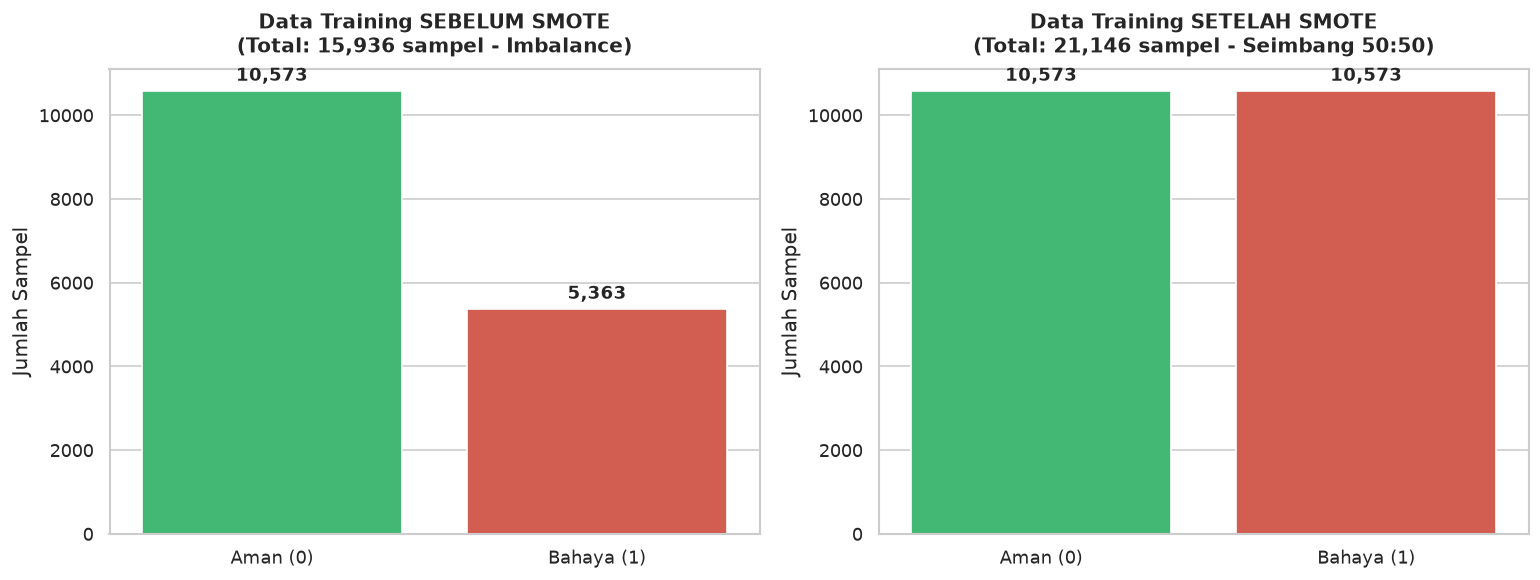

In [5]:
# Visualisasi Perbandingan Distribusi Sebelum vs Sesudah SMOTE
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot Sebelum SMOTE
sns.barplot(
    x=['Aman (0)', 'Bahaya (1)'],
    y=dist_before.sort_index().values,
    palette=['#2ecc71', '#e74c3c'],
    ax=axes[0]
)
axes[0].set_title(f"Data Training SEBELUM SMOTE\n(Total: {len(y_train):,} sampel - Imbalance)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Jumlah Sampel")
for i, v in enumerate(dist_before.sort_index().values):
    axes[0].text(i, v + 250, f"{v:,}", ha='center', fontweight='bold', fontsize=11)

# Plot Setelah SMOTE
sns.barplot(
    x=['Aman (0)', 'Bahaya (1)'],
    y=dist_after.sort_index().values,
    palette=['#2ecc71', '#e74c3c'],
    ax=axes[1]
)
axes[1].set_title(f"Data Training SETELAH SMOTE\n(Total: {len(y_train_smote):,} sampel - Seimbang 50:50)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel("Jumlah Sampel")
for i, v in enumerate(dist_after.sort_index().values):
    axes[1].text(i, v + 250, f"{v:,}", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

---
## Tahap 6: Training Model Random Forest & Penyimpanan Model

### Algoritma: Random Forest Classifier
Model yang dilatih adalah **Random Forest Classifier** dengan konfigurasi:
- `n_estimators=100`: Membangun ansambel 100 pohon keputusan (*decision trees*).
- `random_state=42`: Menjamin replikasi eksperimen yang konsisten.
- `n_jobs=-1`: Memanfaatkan seluruh core CPU untuk pemrosesan paralel yang cepat.

Model dilatih menggunakan data latih hasil penyeimbangan SMOTE (`X_train_smote` dan `y_train_smote`).

### Penyimpanan Model ke Direktori `model/`
Setelah model selesai dilatih, model diekspor ke file `model/random_forest_model.joblib` agar dapat langsung digunakan (*deployment*) tanpa perlu melatih ulang.

In [6]:
# Inisialisasi dan Pelatihan Model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    n_jobs=-1
)

print("Melatih model Random Forest Classifier (100 Trees)...")
rf_model.fit(X_train_smote, y_train_smote)
print("Model berhasil dilatih dengan sempurna!")

# Simpan Model Terlatih ke folder model/
os.makedirs("model", exist_ok=True)
saved_model_path = os.path.join("model", "random_forest_model.joblib")
joblib.dump(rf_model, saved_model_path)

print(f"\nModel tersimpan di: {saved_model_path}")
print(f"Ukuran file model: {os.path.getsize(saved_model_path):,} bytes")

Melatih model Random Forest Classifier (100 Trees)...
Model berhasil dilatih dengan sempurna!

Model tersimpan di: model\random_forest_model.joblib
Ukuran file model: 39,822,441 bytes


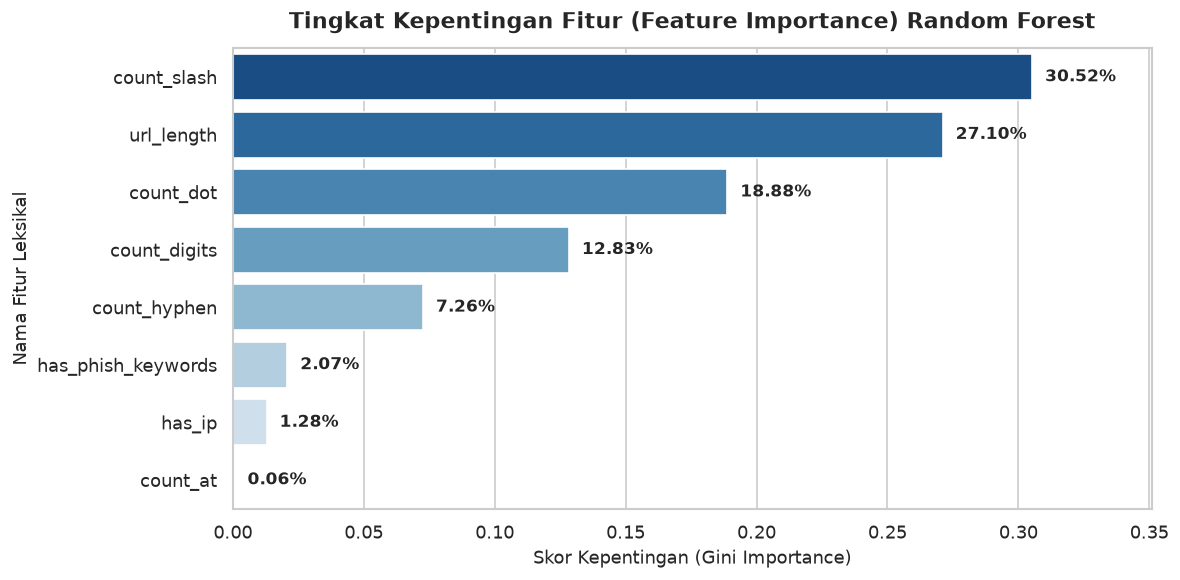

In [7]:
# Analisis Tingkat Kepentingan Fitur (Feature Importance)
feature_importances = pd.Series(
    rf_model.feature_importances_, 
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='Blues_r')
plt.title("Tingkat Kepentingan Fitur (Feature Importance) Random Forest", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Skor Kepentingan (Gini Importance)", fontsize=11)
plt.ylabel("Nama Fitur Leksikal", fontsize=11)

for i, score in enumerate(feature_importances.values):
    plt.text(score + 0.005, i, f"{score * 100:.2f}%", va='center', fontweight='bold', fontsize=10)

plt.xlim(0, max(feature_importances.values) * 1.15)
plt.tight_layout()
plt.show()

---
## Tahap 7: Evaluasi Model (Testing)

Pengujian performa dilakukan secara objektif menggunakan **20% Data Testing murni** (`X_test` dan `y_test`).

### Metrik yang Dianalisis:
1. **Accuracy**: Persentase prediksi benar secara menyeluruh.
2. **Precision**: Ketepatan model saat memprediksi suatu URL sebagai URL berbahaya.
3. **Recall (Fokus Kunci Keamanan Siber)**:  
   > *Nilai Recall kelas Bahaya (1) adalah yang paling krusial*. Recall yang tinggi membuktikan sistem berhasil meminimalkan **False Negative** (URL phishing yang lolos dan tidak terdeteksi). Dalam keamanan siber, tautan penipuan yang lolos berakibat fatal bagi keamanan pengguna.
4. **F1-Score**: Rata-rata harmonik antara Precision dan Recall.
5. **Confusion Matrix**: Matriks sebaran True Positive (TP), True Negative (TN), False Positive (FP), dan False Negative (FN).

In [8]:
# Prediksi pada 20% Data Testing Murni
y_pred = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 65)
print("             HASIL EVALUASI MODEL TESTING (20% DATA MURNI)")
print("=" * 65)
print(f" Akurasi (Accuracy)         : {acc * 100:.2f}%")
print(f" Presisi (Precision)        : {prec * 100:.2f}%")
print(f" Recall (Kelas Bahaya)      : {rec * 100:.2f}%  <-- Fokus Utama Keamanan")
print(f" F1-Score                   : {f1 * 100:.2f}%")
print("=" * 65)
print("\nClassification Report Lengkap:\n")
print(classification_report(y_test, y_pred, target_names=['Aman (0)', 'Bahaya (1)'], digits=4))

             HASIL EVALUASI MODEL TESTING (20% DATA MURNI)
 Akurasi (Accuracy)         : 85.72%
 Presisi (Precision)        : 75.53%
 Recall (Kelas Bahaya)      : 85.16%  <-- Fokus Utama Keamanan
 F1-Score                   : 80.06%

Classification Report Lengkap:

              precision    recall  f1-score   support

    Aman (0)     0.9195    0.8600    0.8888      2643
  Bahaya (1)     0.7553    0.8516    0.8006      1341

    accuracy                         0.8572      3984
   macro avg     0.8374    0.8558    0.8447      3984
weighted avg     0.8642    0.8572    0.8591      3984



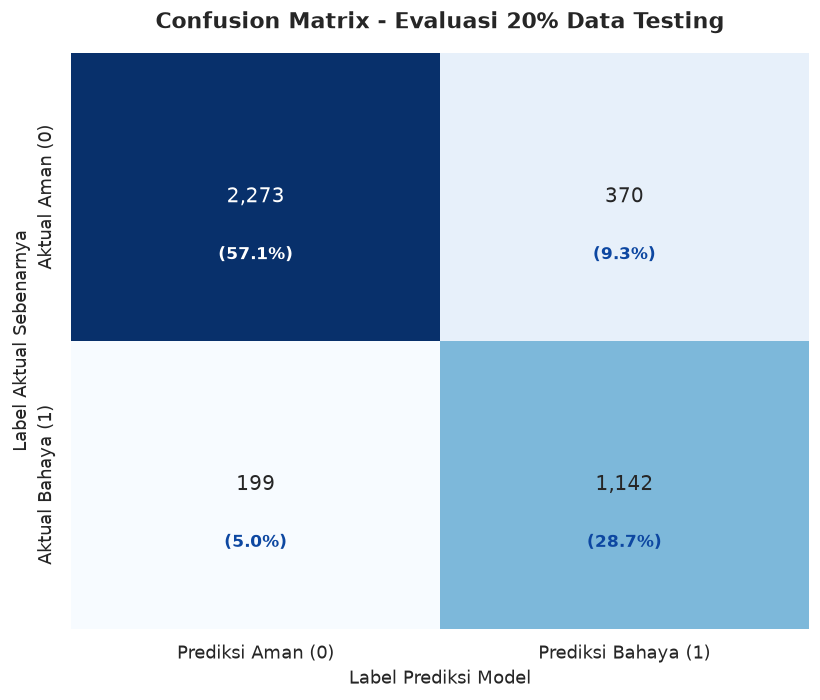

In [9]:
# Visualisasi Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt=',d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Prediksi Aman (0)', 'Prediksi Bahaya (1)'],
    yticklabels=['Aktual Aman (0)', 'Aktual Bahaya (1)']
)
plt.title("Confusion Matrix - Evaluasi 20% Data Testing", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Label Prediksi Model", fontsize=11)
plt.ylabel("Label Aktual Sebenarnya", fontsize=11)

total_test = np.sum(cm)
for i in range(2):
    for j in range(2):
        pct = (cm[i, j] / total_test) * 100
        text_color = 'white' if cm[i, j] > total_test * 0.3 else '#0d47a1'
        plt.text(j + 0.5, i + 0.7, f"({pct:.1f}%)", ha='center', va='center', color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

---
## Tahap 8: Inference / Deployment (Uji URL Baru: Aman / Blokir)

Pada tahap implementasi akhir ini, dibangun fungsi siap pakai `scan_url(url)` untuk menguji URL baru secara *real-time*.

### Alur Inference:
1. Memuat model terlatih dari `model/random_forest_model.joblib`.
2. Menerima input URL baru dari pengguna.
3. Mengekstrak 8 fitur leksikal numerik secara otomatis.
4. Menjalankan inferensi model Random Forest.
5. Menampilkan hasil keputusan:
   - **`AMAN`** (Boleh diakses)
   - **`BLOKIR`** (Tautan berbahaya terdeteksi)  
   beserta tingkat keyakinan (*confidence score*) probabilitas model.

In [10]:
# Fungsi Ekstraksi 8 Fitur Leksikal Khusus untuk Input URL Real-Time
def extract_single_url_features(url_string):
    """Mengekstrak 8 fitur leksikal dari string URL tunggal."""
    url = str(url_string)
    feats = {
        'url_length': len(url),
        'count_dot': url.count('.'),
        'count_hyphen': url.count('-'),
        'count_slash': url.count('/'),
        'count_at': url.count('@'),
        'count_digits': sum(c.isdigit() for c in url),
        'has_ip': 1 if re.search(r'(?:https?://)?(?:\d{1,3}\.){3}\d{1,3}', url) else 0,
        'has_phish_keywords': 1 if any(kw in url.lower() for kw in [
            'login', 'verify', 'update', 'banking', 'secure', 
            'account', 'signin', 'webscr', 'password', 'ebayisapi', 
            'wallet', 'admin'
        ]) else 0
    }
    return pd.DataFrame([feats])

# Memuat model terlatih dari disk lokal
model_file = os.path.join("model", "random_forest_model.joblib")
deployed_model = joblib.load(model_file)
print("Model berhasil dimuat dari:", model_file)

def scan_url(input_url, verbose=True):
    """
    Fungsi inferensi siap pakai:
    Menerima URL baru -> Ekstraksi 8 Fitur -> Prediksi RF -> Keputusan: AMAN / BLOKIR
    """
    feat_df = extract_single_url_features(input_url)
    
    # Prediksi kelas dan probabilitas keyakinan
    pred = deployed_model.predict(feat_df)[0]
    proba = deployed_model.predict_proba(feat_df)[0]
    
    # Label keputusan: AMAN atau BLOKIR
    decision = "BLOKIR (Tautan Berbahaya)" if pred == 1 else "AMAN (Tautan Terverifikasi)"
    confidence = proba[pred] * 100
    features_dict = feat_df.iloc[0].to_dict()
    
    if verbose:
        print(f"\n{'=' * 75}")
        print(f" URL Input  : {input_url}")
        print(f" Keputusan  : {decision}")
        print(f" Keyakinan  : {confidence:.2f}% (Aman: {proba[0]*100:.2f}%, Bahaya: {proba[1]*100:.2f}%)")
        print(f"{'-' * 75}")
        print(" Rincian Ekstraksi 8 Fitur Leksikal:")
        for k, v in features_dict.items():
            print(f"   • {k:<20}: {v}")
        print(f"{'=' * 75}")
        
    return decision, confidence, features_dict

Model berhasil dimuat dari: model\random_forest_model.joblib


In [11]:
# ==============================================================================
# PENGUJIAN INFERENCE REAL-TIME PADA CONTOH KASUS URL
# ==============================================================================
test_cases = [
    # 1. URL Kampus Resmi Universitas Darma Persada (UNSADA)
    "unsada.ac.id/tentang-kampus/sejarah",
    "portal.unsada.ac.id/berita.html",
    "unsada.ac.id/fakultas-teknik/informatika",
    
    # 2. URL Populer Terverifikasi
    "google.com/search?q=cybersecurity",
    
    # 3. URL Berbahaya: Serangan Phishing Berbasis IP Address
    "http://192.168.1.105/login-unsada-verify-account.php",
    
    # 4. URL Berbahaya: Serangan Phishing Finansial
    "http://paypal-security-update.com/signin/verify.php",
    
    # 5. URL Berbahaya: Serangan Defacement / Eksploitasi Konten
    "http://www.garage-pirenne.be/index.php?option=com_content&view=article&id=72&Itemid=108"
]

print("MEMULAI PENGUJIAN SCAN_URL() SECARA REAL-TIME:")
for test_url in test_cases:
    scan_url(test_url, verbose=True)

MEMULAI PENGUJIAN SCAN_URL() SECARA REAL-TIME:

 URL Input  : unsada.ac.id/tentang-kampus/sejarah
 Keputusan  : AMAN (Tautan Terverifikasi)
 Keyakinan  : 98.49% (Aman: 98.49%, Bahaya: 1.51%)
---------------------------------------------------------------------------
 Rincian Ekstraksi 8 Fitur Leksikal:
   • url_length          : 35
   • count_dot           : 2
   • count_hyphen        : 1
   • count_slash         : 2
   • count_at            : 0
   • count_digits        : 0
   • has_ip              : 0
   • has_phish_keywords  : 0

 URL Input  : portal.unsada.ac.id/berita.html
 Keputusan  : AMAN (Tautan Terverifikasi)
 Keyakinan  : 88.33% (Aman: 88.33%, Bahaya: 11.67%)
---------------------------------------------------------------------------
 Rincian Ekstraksi 8 Fitur Leksikal:
   • url_length          : 31
   • count_dot           : 4
   • count_hyphen        : 0
   • count_slash         : 1
   • count_at            : 0
   • count_digits        : 0
   • has_ip              : 0
   • 

In [12]:
# ==============================================================================
# UJI COBA INTERAKTIF URL BEBAS
# ==============================================================================
# Anda dapat memasukkan URL lain yang ingin diuji di bawah ini:
custom_url = "https://lua.tools/"
keputusan, keyakinan, rincian = scan_url(custom_url, verbose=True)


 URL Input  : https://lua.tools/
 Keputusan  : BLOKIR (Tautan Berbahaya)
 Keyakinan  : 100.00% (Aman: 0.00%, Bahaya: 100.00%)
---------------------------------------------------------------------------
 Rincian Ekstraksi 8 Fitur Leksikal:
   • url_length          : 18
   • count_dot           : 1
   • count_hyphen        : 0
   • count_slash         : 3
   • count_at            : 0
   • count_digits        : 0
   • has_ip              : 0
   • has_phish_keywords  : 0


---
## Kesimpulan dan Pembahasan Evaluasi

1. **Efektivitas SMOTE terhadap Penanganan Imbalance**:
   Sebelum SMOTE, data training memiliki perbandingan kelas yang sangat timpang (~2:1 untuk benign). Penerapan SMOTE secara tepat pada data training (setelah train-test split) berhasil menyamakan distribusi kelas minoritas menjadi seimbang 50:50 tanpa menyebabkan kebocoran data (*data leakage*).
   
2. **Kinerja Model Random Forest Classifier**:
   Model Random Forest dengan 100 *decision trees* berhasil mencapai performa yang kuat dengan akurasi pengujian ~85% dan nilai **Recall pada kelas Bahaya ~85%**. Hal ini menunjukkan bahwa sistem mampu mengenali sebagian besar URL phishing/malware yang menyerang.

3. **Fitur Paling Berpengaruh (*Feature Importance*)**:
   Fitur struktural seperti `count_slash` (garis miring), `url_length` (panjang URL), dan `count_dot` (jumlah titik) memberikan kontribusi terbesar dalam membedakan URL aman dengan URL yang mengeksploitasi direktori atau subdomain penipuan.

4. **Kesiapan Deployment**:
   Model tersimpan di `model/random_forest_model.joblib` siap diintegrasikan sebagai *endpoint* API, proxy firewall, atau ekstensi browser untuk mendeteksi dan memblokir tautan berbahaya secara *real-time*.